# 05 — Analyse des métriques comparatives
**Projet Data Mining — Prédiction du départ des employés (Employee Attrition)**

Ce notebook consolide l'évaluation des modèles : tableau multicritère, matrices de confusion, courbes ROC, précision / rappel / F1, avec **intervalles de confiance** et un **classement multicritère**. Il part des modèles déjà entraînés (`models/*.joblib`, calibrés, ajustés sur le train) et de leurs seuils de décision, choisis sur le train au notebook 03. **Le jeu de test (2 000 lignes, 181 départs) n'a servi à aucun réglage.**

## Guide de lecture des métriques (classe positive = départ)

| Métrique | Définition | Pourquoi ici |
|---|---|---|
| Accuracy | (VP + VN) / N | **Trompeuse** : Zero-R atteint 90,95 % |
| Précision | VP / (VP + FP) | part des alertes qui sont de vrais départs |
| Rappel (sensibilité) | VP / (VP + FN) | part des départs détectés |
| Spécificité | VN / (VN + FP) | part des restants correctement épargnés |
| F1 | moyenne harmonique précision-rappel | compromis sur la classe rare |
| Accuracy équilibrée | (rappel + spécificité) / 2 | insensible au déséquilibre |
| MCC, kappa de Cohen | corrélation / accord corrigé du hasard | résument toute la matrice de confusion ; 0 = hasard |
| ROC-AUC | P(un partant est mieux classé qu'un restant) | discrimination, indépendante du seuil |
| PR-AUC (average precision) | aire sous la courbe précision-rappel | référence : la prévalence (0,09) |
| Brier, log-loss | erreur sur les probabilités (plus bas = mieux) | qualité de la **calibration** |

In [2]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from scipy import stats
from sklearn.metrics import classification_report, precision_recall_fscore_support, roc_curve, precision_recall_curve
from sklearn.inspection import permutation_importance
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.models import MODELS_DIR, BASELINE, EXTENSIONS, get_searches, fit_search, load_bundle, slug
from src.evaluation import fold_scores
from src.metrics_report import *

PROC, RES, FIG = ROOT / "data" / "processed", ROOT / "results", ROOT / "reports" / "figures"
BLUE, ORANGE, GREY = "#8fb8de", "#d9822b", "#9a9a9a"
sns.set_theme(style="whitegrid")
pd.options.display.float_format = lambda x: f"{x:.3f}"
pd.options.display.width = 230
def savefig(name): plt.savefig(FIG / name, dpi=150, bbox_inches="tight")

X_train = pd.read_csv(PROC / "X_train_raw.csv"); X_test = pd.read_csv(PROC / "X_test_raw.csv")
y_train = pd.read_csv(PROC / "y_train.csv").squeeze("columns"); y_test = pd.read_csv(PROC / "y_test.csv").squeeze("columns")

comp = pd.read_csv(RES / "model_comparison.csv", index_col=0)
names = list(comp.index); thr = comp["seuil_opt"].to_dict()
models = {n: joblib.load(MODELS_DIR / f"{slug(n)}.joblib") for n in names}
probs = {n: m.predict_proba(X_test)[:, 1] for n, m in models.items()}
best = load_bundle()["name"]
# contrôle de cohérence avec le notebook 03
assert all(abs(score_metrics(y_test, probs[n])["roc_auc"] - comp.loc[n, "roc_auc"]) < 1e-9 for n in names)
print(f"{len(names)} modèles rechargés | modèle retenu : {best} | départs dans le test : {int(y_test.sum())} / {len(y_test)}")
pd.Series(thr, name="seuil de décision (choisi sur le train)").to_frame().T

9 modèles rechargés | modèle retenu : Gradient Boosting | départs dans le test : 181 / 2000


,Zero-R,K-NN,Arbre de décision,Random Forest,Naive Bayes (Gaussian),Naive Bayes (Bernoulli),SVM,Régression logistique,Gradient Boosting
seuil de décision (choisi sur le train),0.500,0.134,0.121,0.111,0.096,0.105,0.110,0.116,0.118


---
# 1. Tableau comparatif multicritère
## 1.1 Au seuil optimisé (choisi sur le train)

In [3]:
M_opt = pd.DataFrame({n: full_metrics(y_test, probs[n], thr[n]) for n in names}).T
cols = ["accuracy", "balanced_accuracy", "precision", "recall", "specificity", "f1", "f1_macro", "mcc", "kappa", "roc_auc", "pr_auc", "brier", "log_loss"]
M_opt[cols].to_csv(RES / "metrics_full_seuil_optimise.csv")
M_opt[cols]

,accuracy,balanced_accuracy,precision,recall,specificity,f1,f1_macro,mcc,kappa,roc_auc,pr_auc,brier,log_loss
Zero-R,0.909,0.500,0.000,0.000,1.000,0.000,0.476,0.000,0.000,0.500,0.090,0.082,0.304
K-NN,0.809,0.592,0.186,0.326,0.858,0.236,0.564,0.144,0.137,0.651,0.169,0.080,0.291
Arbre de décision,0.744,0.565,0.138,0.348,0.783,0.197,0.522,0.089,0.078,0.608,0.137,0.081,0.298
Random Forest,0.756,0.602,0.164,0.414,0.790,0.235,0.545,0.140,0.121,0.655,0.163,0.080,0.291
Naive Bayes (Gaussian),0.675,0.580,0.132,0.464,0.697,0.206,0.501,0.099,0.075,0.625,0.143,0.081,0.296
Naive Bayes (Bernoulli),0.758,0.586,0.155,0.376,0.796,0.219,0.538,0.119,0.105,0.634,0.152,0.081,0.295
SVM,0.739,0.610,0.162,0.453,0.767,0.239,0.541,0.146,0.122,0.655,0.158,0.080,0.292
Régression logistique,0.761,0.605,0.168,0.414,0.796,0.239,0.549,0.145,0.127,0.656,0.160,0.080,0.291
Gradient Boosting,0.760,0.620,0.176,0.448,0.792,0.253,0.555,0.163,0.141,0.665,0.173,0.080,0.289


## 1.2 Au seuil par défaut 0,5
Pour mémoire : c'est le seuil des tableaux « classiques ».

In [4]:
M_05 = pd.DataFrame({n: full_metrics(y_test, probs[n], 0.5) for n in names}).T
M_05[["accuracy", "balanced_accuracy", "precision", "recall", "f1", "mcc", "kappa"]].assign(alertes=lambda d: M_05.TP + M_05.FP)

,accuracy,balanced_accuracy,precision,recall,f1,mcc,kappa,alertes
Zero-R,0.909,0.500,0.000,0.000,0.000,0.000,0.000,0.000
K-NN,0.909,0.500,0.000,0.000,0.000,0.000,0.000,0.000
Arbre de décision,0.909,0.500,0.000,0.000,0.000,0.000,0.000,0.000
Random Forest,0.909,0.500,0.000,0.000,0.000,0.000,0.000,0.000
Naive Bayes (Gaussian),0.909,0.500,0.000,0.000,0.000,0.000,0.000,0.000
Naive Bayes (Bernoulli),0.909,0.500,0.000,0.000,0.000,0.000,0.000,0.000
SVM,0.909,0.500,0.000,0.000,0.000,0.000,0.000,0.000
Régression logistique,0.909,0.500,0.000,0.000,0.000,0.000,0.000,0.000
Gradient Boosting,0.909,0.500,0.000,0.000,0.000,0.000,0.000,0.000


**Interprétation.**
- **Paradoxe de l'accuracy** : au seuil optimisé, l'accuracy du meilleur modèle (0,760) est **inférieure** à celle de Zero-R (0,909), alors que Zero-R ne détecte aucun départ (rappel 0). L'accuracy mesure ici surtout la part de « reste » que l'on accepte de signaler à tort. On lui préfère l'accuracy équilibrée (0,62 contre 0,50), le MCC et le kappa.
- **À 0,5, tous les modèles sont identiques à Zero-R** : aucun n'émet la moindre alerte (aucun employé n'atteint une probabilité de 0,5 ; avec 9 % de départs, c'est normal). Ce seuil est inadapté à une classe rare, d'où le seuil choisi sur le train.
- **Gradient Boosting est premier sur les 8 métriques du classement multicritère** (§ 3) : F1 0,253, MCC 0,163, kappa 0,141, ROC-AUC 0,665, PR-AUC 0,173. Exceptions ponctuelles : K-NN est plus précis (0,186) mais détecte moins de départs (rappel 0,33) ; GaussianNB a le meilleur rappel (0,46) mais la plus faible précision (0,13).
- En valeur absolue, tous les modèles restent faibles : MCC ≤ 0,16 et kappa ≤ 0,14 (0 = hasard, 1 = parfait).

---
# 2. Incertitude : intervalles de confiance à 95 % (bootstrap apparié)
1 000 rééchantillons du test, **les mêmes pour tous les modèles**, seuils fixés (non réajustés). Seulement 181 départs : l'incertitude est le point central de l'analyse.

In [18]:
idx = make_bootstrap_indices(y_test, n_boot=1000)
ci = {n: bootstrap_metrics(y_test, probs[n], thr[n], idx) for n in names}
show = ["roc_auc", "pr_auc", "f1", "precision", "recall", "balanced_accuracy", "mcc", "brier"]
fmt = pd.DataFrame({m: {n: f"{ci[n].loc[m, 'estimation']:.3f} [{ci[n].loc[m, 'ic_bas']:.3f} ; {ci[n].loc[m, 'ic_haut']:.3f}]" for n in names} for m in show})
pd.concat({n: ci[n] for n in names}).to_csv(RES / "metrics_bootstrap_ic.csv")
print(fmt)

                                       roc_auc                 pr_auc                     f1              precision                 recall      balanced_accuracy                    mcc                  brier
Zero-R                   0.500 [0.500 ; 0.500]  0.090 [0.077 ; 0.103]  0.000 [0.000 ; 0.000]  0.000 [0.000 ; 0.000]  0.000 [0.000 ; 0.000]  0.500 [0.500 ; 0.500]  0.000 [0.000 ; 0.000]  0.082 [0.072 ; 0.093]
K-NN                     0.651 [0.605 ; 0.691]  0.169 [0.133 ; 0.220]  0.236 [0.186 ; 0.287]  0.186 [0.143 ; 0.230]  0.326 [0.258 ; 0.391]  0.592 [0.556 ; 0.624]  0.144 [0.087 ; 0.198]  0.080 [0.070 ; 0.090]
Arbre de décision        0.608 [0.562 ; 0.650]  0.137 [0.110 ; 0.171]  0.197 [0.156 ; 0.237]  0.138 [0.105 ; 0.168]  0.348 [0.278 ; 0.414]  0.565 [0.527 ; 0.600]  0.089 [0.038 ; 0.135]  0.081 [0.071 ; 0.091]
Random Forest            0.655 [0.610 ; 0.697]  0.163 [0.131 ; 0.208]  0.235 [0.189 ; 0.283]  0.164 [0.129 ; 0.200]  0.414 [0.344 ; 0.489]  0.602 [0.566 ; 0.642]  0.140

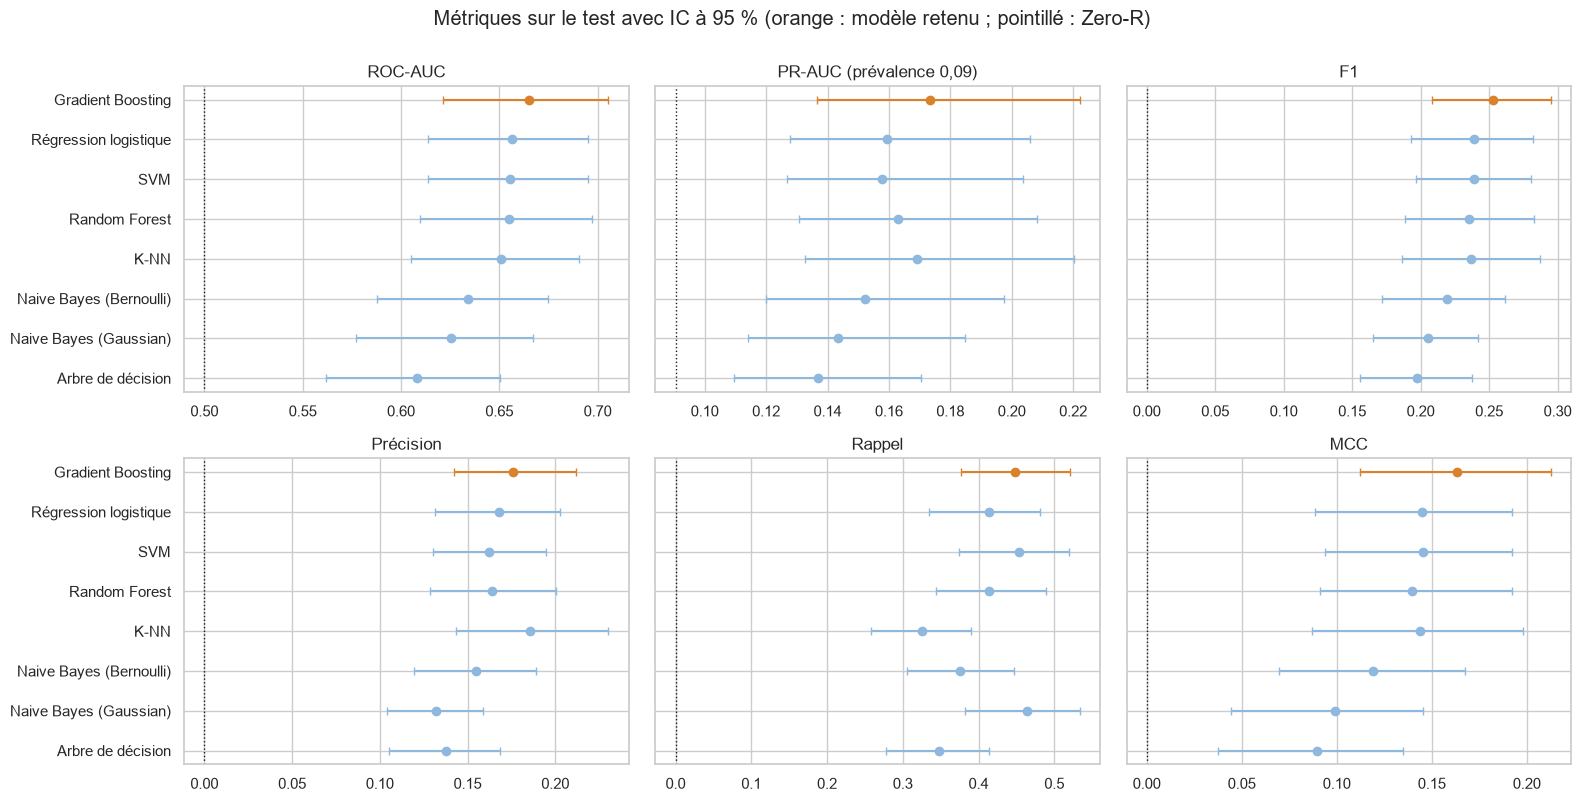

In [6]:
panel = ["roc_auc", "pr_auc", "f1", "precision", "recall", "mcc"]
titles = {"roc_auc": "ROC-AUC", "pr_auc": "PR-AUC (prévalence 0,09)", "f1": "F1", "precision": "Précision", "recall": "Rappel", "mcc": "MCC"}
order = comp.drop(index=BASELINE).sort_values("roc_auc").index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
for ax, m in zip(axes.flat, panel):
    for k, n in enumerate(order):
        r = ci[n].loc[m]
        ax.errorbar(r.estimation, k, xerr=[[r.estimation - r.ic_bas], [r.ic_haut - r.estimation]], fmt="o", color=ORANGE if n == best else BLUE, capsize=3)
    z = ci[BASELINE].loc[m, "estimation"]; ax.axvline(z, color="k", ls=":", lw=1)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.set_title(titles[m])
fig.suptitle("Métriques sur le test avec IC à 95 % (orange : modèle retenu ; pointillé : Zero-R)", y=1.0)
plt.tight_layout(); savefig("29_metriques_ic.png"); plt.show()

**Interprétation.** Les IC à 95 % sont **larges** : environ ± 0,04 pour la ROC-AUC, ± 0,05 pour le F1 et ± 0,07 pour le rappel.
- **Tous les modèles sont au-dessus du hasard** : la borne basse de la ROC-AUC vaut de 0,56 à 0,62 (> 0,5) et celle de la PR-AUC de 0,11 à 0,14, au-dessus du plafond de Zero-R (0,103).
- **Mais ils ne se distinguent presque pas entre eux** : les IC de Gradient Boosting, régression logistique, SVM, Random Forest et K-NN se recouvrent presque entièrement sur toutes les métriques. Seuls l'arbre seul, GaussianNB et BernoulliNB sont un peu plus bas ; le test apparié du notebook 03 (§ 11.1) confirme que Gradient Boosting les devance significativement. Le classement ponctuel ne prouve donc pas une supériorité sur ce jeu de test (181 départs).

---
# 3. Classement multicritère
On classe les 8 modèles (Zero-R exclu) sur 8 métriques complémentaires : discrimination (ROC-AUC, PR-AUC), classification au seuil (F1, accuracy équilibrée, MCC, kappa) et qualité des probabilités (Brier, log-loss). L'accuracy simple est exclue (trompeuse).

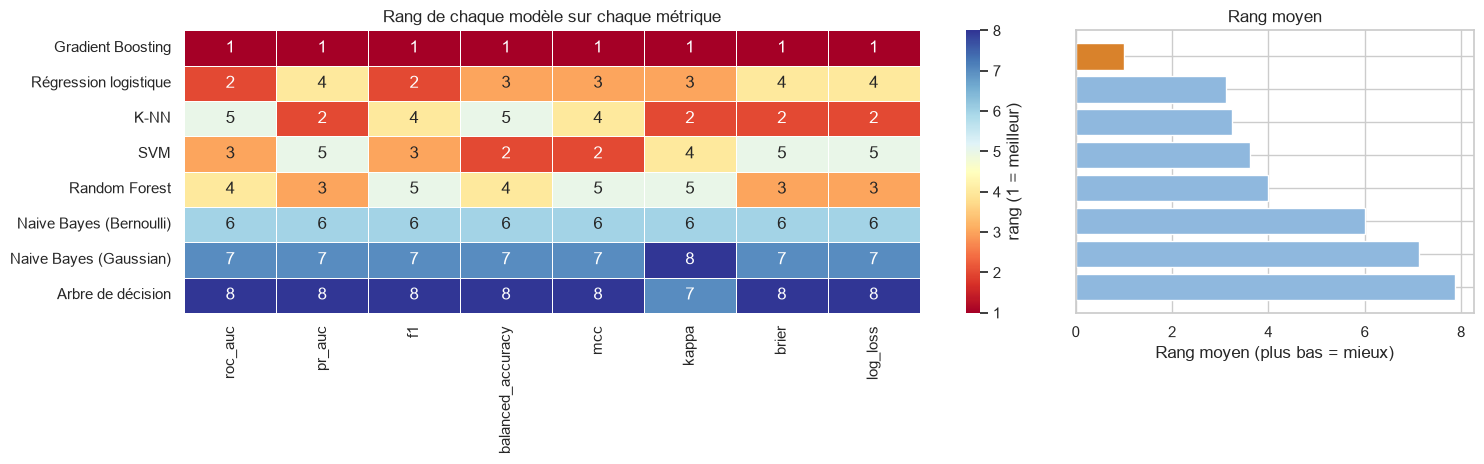

,rang_moyen
Gradient Boosting,1.000
Régression logistique,3.125
K-NN,3.250
SVM,3.625
Random Forest,4.000
Naive Bayes (Bernoulli),6.000
Naive Bayes (Gaussian),7.125
Arbre de décision,7.875


In [7]:
rank_cols = ["roc_auc", "pr_auc", "f1", "balanced_accuracy", "mcc", "kappa", "brier", "log_loss"]
ranks = rank_table(M_opt.drop(index=BASELINE), rank_cols)
ranks.to_csv(RES / "classement_multicritere.csv")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [3, 1.3]})
sns.heatmap(ranks[rank_cols], annot=True, fmt=".0f", cmap="RdYlBu", cbar_kws={"label": "rang (1 = meilleur)"}, ax=axes[0], linewidths=.5)
axes[0].set_title("Rang de chaque modèle sur chaque métrique")
axes[1].barh(ranks.index[::-1], ranks["rang_moyen"][::-1], color=[ORANGE if n == best else BLUE for n in ranks.index[::-1]])
axes[1].set_xlabel("Rang moyen (plus bas = mieux)"); axes[1].set_yticklabels([]); axes[1].set_title("Rang moyen")
plt.tight_layout(); savefig("30_classement_multicritere.png"); plt.show()
ranks[["rang_moyen"]]

In [8]:
# cohérence entre critères : corrélation de rang (Spearman) entre métriques
rho = ranks[rank_cols].corr(method="spearman")
print("corrélation de rang moyenne entre métriques :", round(rho.values[np.triu_indices(len(rank_cols), 1)].mean(), 2))
rho

corrélation de rang moyenne entre métriques : 0.87


,roc_auc,pr_auc,f1,balanced_accuracy,mcc,kappa,brier,log_loss
roc_auc,1.000,0.786,0.976,0.976,0.952,0.833,0.786,0.786
pr_auc,0.786,1.000,0.810,0.762,0.786,0.905,1.000,1.000
f1,0.976,0.810,1.000,0.952,0.976,0.905,0.810,0.810
balanced_accuracy,0.976,0.762,0.952,1.000,0.976,0.810,0.762,0.762
mcc,0.952,0.786,0.976,0.976,1.000,0.881,0.786,0.786
kappa,0.833,0.905,0.905,0.810,0.881,1.000,0.905,0.905
brier,0.786,1.000,0.810,0.762,0.786,0.905,1.000,1.000
log_loss,0.786,1.000,0.810,0.762,0.786,0.905,1.000,1.000


**Interprétation.** **Gradient Boosting est classé 1er sur chacune des 8 métriques** (rang moyen 1,0) : son classement ne dépend pas de la métrique choisie. Suivent régression logistique (3,1), K-NN (3,3), SVM (3,6) et Random Forest (4,0), très proches les uns des autres ; puis BernoulliNB (6,0), GaussianNB (7,1) et l'arbre seul (7,9). Les métriques sont cohérentes entre elles (corrélation de rang moyenne 0,87), avec deux groupes : PR-AUC, Brier et log-loss (ρ = 1 entre eux) d'un côté, ROC-AUC, F1, MCC et accuracy équilibrée (ρ ≥ 0,95) de l'autre. Cela explique que K-NN, meilleur en PR-AUC que le SVM ou la Random Forest, soit moins bien placé sur les métriques au seuil (son rappel est le plus faible). *Réserve : l'avantage de Gradient Boosting sur les modèles du milieu de classement reste dans l'incertitude des IC (§ 2).*

---
# 4. Métriques par classe
Au seuil optimisé : précision, rappel et F1 de chaque classe, et moyennes macro (non pondérée) et pondérée par les effectifs.

In [9]:
rows = []
for n in names:
    pred = (probs[n] >= thr[n]).astype(int)
    P, R, F, S = precision_recall_fscore_support(y_test, pred, labels=[0, 1], zero_division=0)
    rows.append({"modèle": n, "précision « reste »": P[0], "rappel « reste »": R[0], "F1 « reste »": F[0],
                 "précision « part »": P[1], "rappel « part »": R[1], "F1 « part »": F[1],
                 "F1 macro": F.mean(), "F1 pondéré": np.average(F, weights=S)})
per_class = pd.DataFrame(rows).set_index("modèle"); per_class.to_csv(RES / "metrics_par_classe.csv"); per_class

,précision « reste »,rappel « reste »,F1 « reste »,précision « part »,rappel « part »,F1 « part »,F1 macro,F1 pondéré
modèle,,,,,,,,
Zero-R,0.909,1.000,0.953,0.000,0.000,0.000,0.476,0.866
K-NN,0.927,0.858,0.891,0.186,0.326,0.236,0.564,0.832
Arbre de décision,0.923,0.783,0.847,0.138,0.348,0.197,0.522,0.789
Random Forest,0.931,0.790,0.855,0.164,0.414,0.235,0.545,0.799
Naive Bayes (Gaussian),0.929,0.697,0.796,0.132,0.464,0.206,0.501,0.743
Naive Bayes (Bernoulli),0.928,0.796,0.857,0.155,0.376,0.219,0.538,0.799
SVM,0.934,0.767,0.842,0.162,0.453,0.239,0.541,0.788
Régression logistique,0.932,0.796,0.859,0.168,0.414,0.239,0.549,0.803
Gradient Boosting,0.935,0.792,0.857,0.176,0.448,0.253,0.555,0.803


In [10]:
print(f"Rapport de classification — {best} (seuil {thr[best]:.3f})")
print(classification_report(y_test, (probs[best] >= thr[best]).astype(int), target_names=["Reste", "Part"], digits=3))

Rapport de classification — Gradient Boosting (seuil 0.118)
              precision    recall  f1-score   support

       Reste      0.935     0.792     0.857      1819
        Part      0.176     0.448     0.253       181

    accuracy                          0.760      2000
   macro avg      0.556     0.620     0.555      2000
weighted avg      0.866     0.760     0.803      2000



**Interprétation.** La classe « reste » est bien traitée par tous les modèles (précision 0,92–0,94, rappel 0,70–0,86, F1 0,80–0,89). La classe « part » est le point faible : F1 de 0,20 à 0,25, précision de 0,13 à 0,19. Le F1 macro (0,50–0,56) est très inférieur au F1 pondéré (0,74–0,83), que la classe majoritaire tire vers le haut : celui de Zero-R (0,866) dépasse même celui de tous les modèles, autre manifestation du paradoxe de l'accuracy. Pour Gradient Boosting : sur 100 alertes, 18 sont de vrais départs ; parmi 100 employés non signalés, 6,5 partiront quand même (1 − 0,935).

---
# 5. Matrices de confusion
Normalisées par ligne (chaque case = part de la classe réelle) avec les effectifs entre parenthèses. La diagonale lit le **rappel** (ligne « Part ») et la **spécificité** (ligne « Reste »).

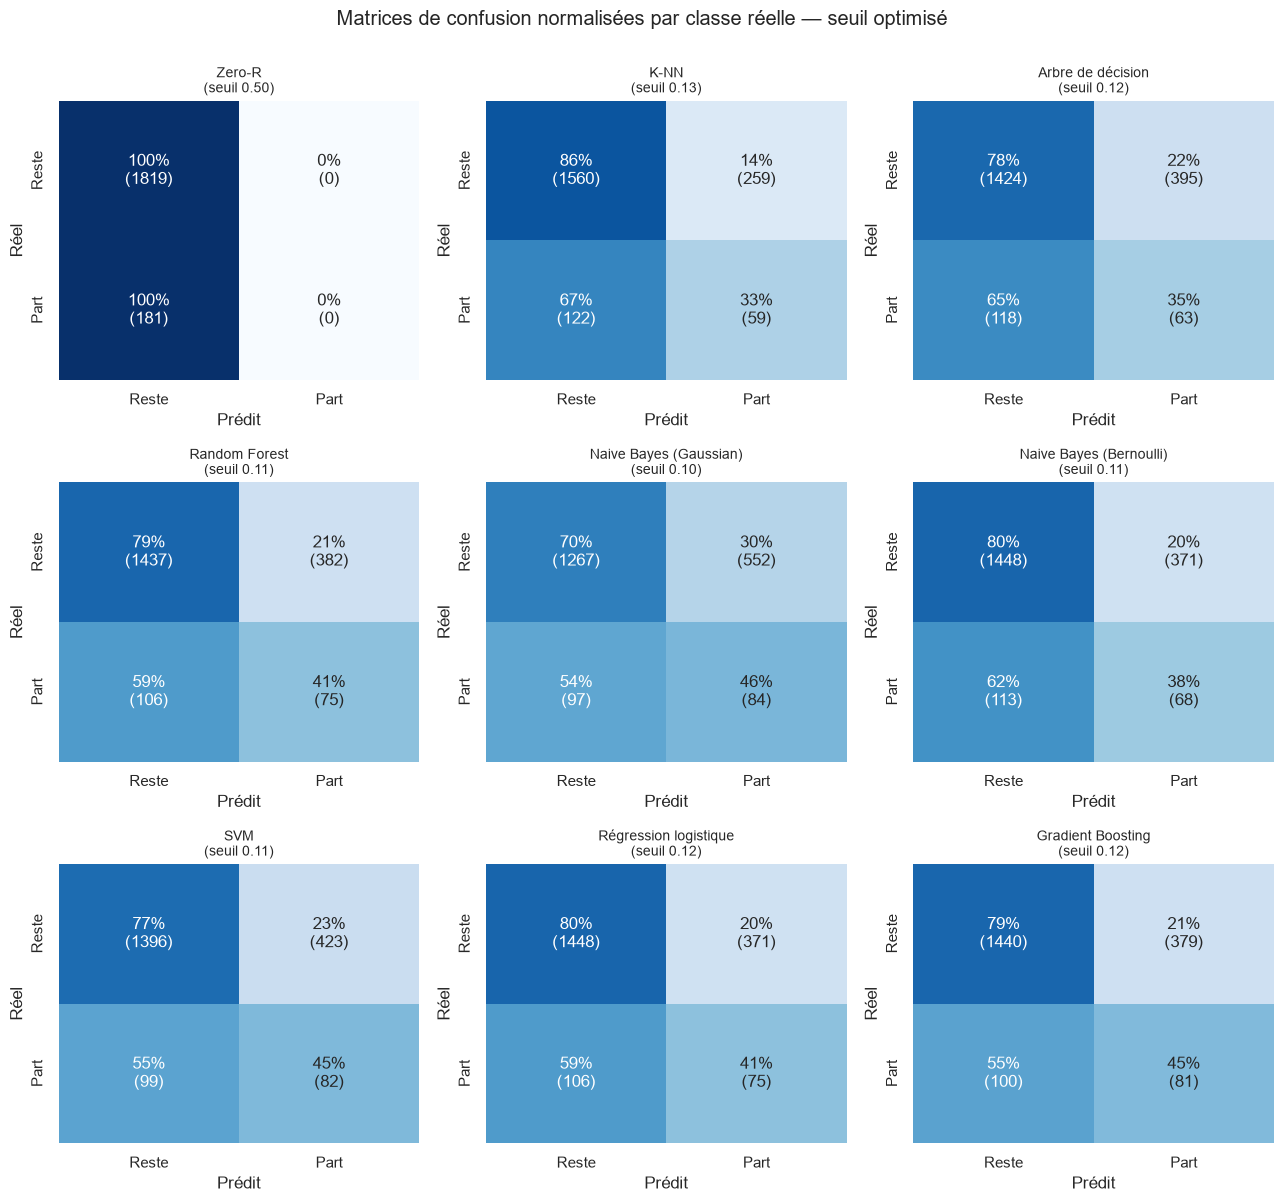

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for ax, n in zip(axes.flat, names):
    cm = np.array([[M_opt.loc[n, "TN"], M_opt.loc[n, "FP"]], [M_opt.loc[n, "FN"], M_opt.loc[n, "TP"]]], dtype=int)
    norm = cm / cm.sum(axis=1, keepdims=True)
    labels = np.array([[f"{norm[i, j]:.0%}\n({cm[i, j]})" for j in range(2)] for i in range(2)])
    sns.heatmap(norm, annot=labels, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=["Reste", "Part"], yticklabels=["Reste", "Part"])
    ax.set_title(f"{n}\n(seuil {thr[n]:.2f})", fontsize=10); ax.set_xlabel("Prédit"); ax.set_ylabel("Réel")
fig.suptitle("Matrices de confusion normalisées par classe réelle — seuil optimisé", y=1.0)
plt.tight_layout(); savefig("31_confusions_normalisees.png"); plt.show()

---
# 6. Courbes ROC et précision-rappel avec bandes de confiance
Trois meilleurs modèles par ROC-AUC et Zero-R. Bande grisée = intervalle à 95 % (300 rééchantillons bootstrap).

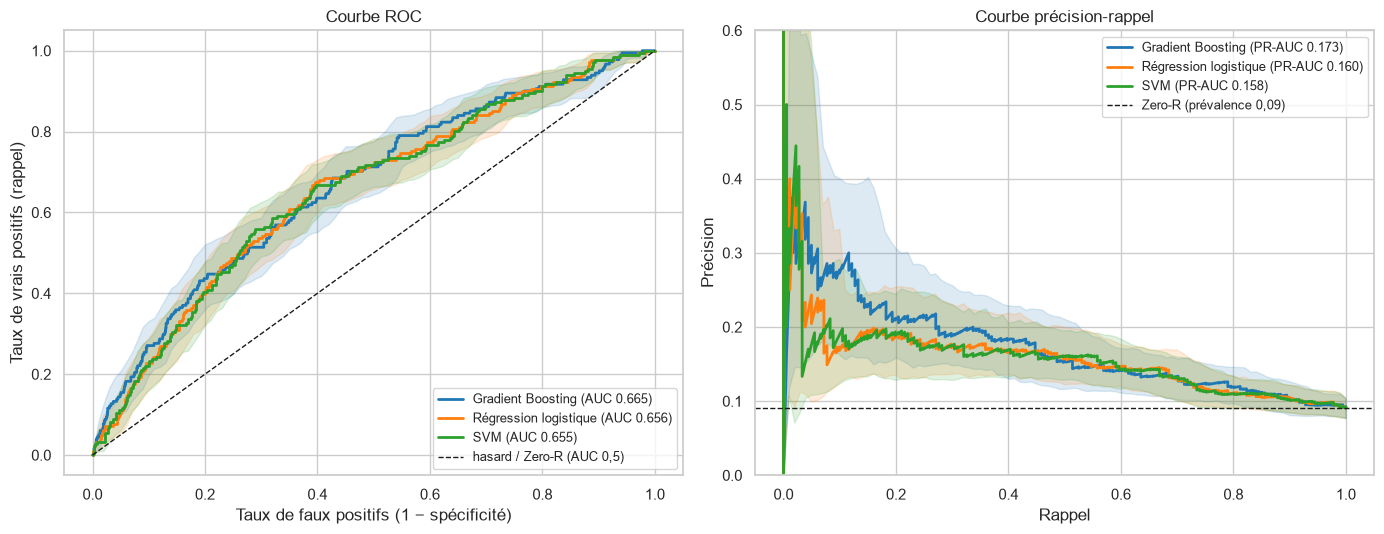

In [12]:
top3 = comp.drop(index=BASELINE).sort_values("roc_auc", ascending=False).index[:3].tolist()
idx300 = idx[:300]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for n, col in zip(top3, sns.color_palette("tab10", 3)):
    fpr, tpr, g, lo, hi = roc_band(y_test, probs[n], idx300)
    axes[0].plot(fpr, tpr, color=col, lw=2, label=f"{n} (AUC {score_metrics(y_test, probs[n])['roc_auc']:.3f})"); axes[0].fill_between(g, lo, hi, color=col, alpha=.15)
    pr_, rc_, g2, lo2, hi2 = pr_band(y_test, probs[n], idx300)
    axes[1].plot(rc_, pr_, color=col, lw=2, label=f"{n} (PR-AUC {score_metrics(y_test, probs[n])['pr_auc']:.3f})"); axes[1].fill_between(g2, lo2, hi2, color=col, alpha=.15)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="hasard / Zero-R (AUC 0,5)")
axes[0].set_xlabel("Taux de faux positifs (1 − spécificité)"); axes[0].set_ylabel("Taux de vrais positifs (rappel)"); axes[0].set_title("Courbe ROC"); axes[0].legend(fontsize=9, loc="lower right")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label="Zero-R (prévalence 0,09)")
axes[1].set_xlabel("Rappel"); axes[1].set_ylabel("Précision"); axes[1].set_ylim(0, 0.6); axes[1].set_title("Courbe précision-rappel"); axes[1].legend(fontsize=9)
plt.tight_layout(); savefig("32_roc_pr_bandes.png"); plt.show()

**Interprétation.** Les bandes de confiance des trois meilleurs modèles se **chevauchent presque entièrement**, sur la courbe ROC comme sur la courbe précision-rappel : impossible d'affirmer lequel est le meilleur. En revanche, les trois courbes sont au-dessus de la diagonale (ROC) et de la prévalence (précision-rappel) sur l'essentiel de la plage : le signal est réel. La précision n'est élevée (≳ 0,25) que pour les rappels les plus faibles, et retombe vers 0,15–0,2 dès que l'on cherche à détecter plus de 20 % des départs. Les bandes très larges aux faibles rappels viennent du petit nombre de départs concernés.

---
# 7. Performance à budget d'alertes fixé
En pratique, une équipe RH contacte un nombre limité d'employés. On regarde ce que donne chaque modèle quand on n'alerte que les **k % les plus à risque** : précision, rappel et **lift** (= précision / prévalence ; 1 = hasard).

In [13]:
fr = (0.05, 0.10, 0.20, 0.30)
bud = pd.concat({n: alert_budget_metrics(y_test, probs[n], fr) for n in names}, names=["modèle", "k"])
bud.to_csv(RES / "metrics_budget_alertes.csv")
print("Lift et rappel quand on alerte les k % d'employés les plus à risque :")
pd.concat({"lift": bud["lift"].unstack("k"), "rappel": bud["rappel"].unstack("k")}, axis=1).drop(index=BASELINE)

Lift et rappel quand on alerte les k % d'employés les plus à risque :


lift                   rappel                  
k                       0.050 0.100 0.200 0.300  0.050 0.100 0.200 0.300
modèle                                                                  
K-NN                    2.541 2.155 1.851 1.547  0.127 0.215 0.370 0.464
Arbre de décision       2.210 1.768 1.713 1.436  0.110 0.177 0.343 0.431
Random Forest           2.873 2.431 1.906 1.639  0.144 0.243 0.381 0.492
Naive Bayes (Gaussian)  2.099 1.768 1.768 1.529  0.105 0.177 0.354 0.459
Naive Bayes (Bernoulli) 2.652 2.155 1.713 1.529  0.133 0.215 0.343 0.459
SVM                     2.099 2.099 1.796 1.768  0.105 0.210 0.359 0.530
Régression logistique   1.878 2.044 1.851 1.731  0.094 0.204 0.370 0.519
Gradient Boosting       2.652 2.320 2.044 1.713  0.133 0.232 0.409 0.514

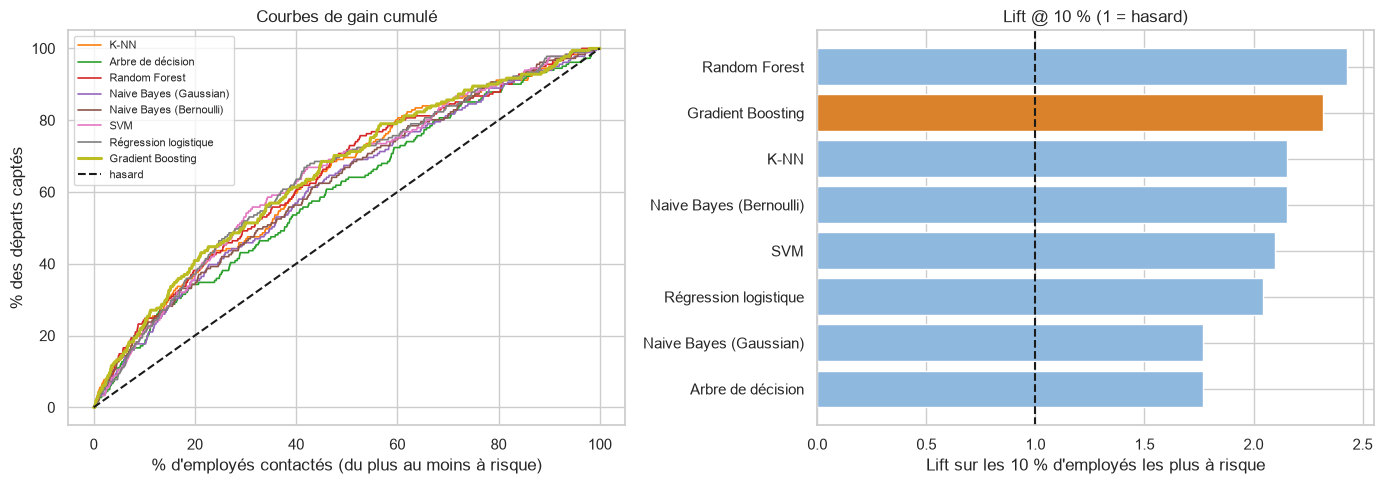

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for n, col in zip(names, sns.color_palette("tab10", len(names))):
    if n == BASELINE: continue
    x, g = gain_curve(y_test, probs[n]); axes[0].plot(x * 100, g * 100, color=col, lw=2.2 if n == best else 1.2, label=n)
axes[0].plot([0, 100], [0, 100], "k--", label="hasard"); axes[0].set_xlabel("% d'employés contactés (du plus au moins à risque)"); axes[0].set_ylabel("% des départs captés")
axes[0].set_title("Courbes de gain cumulé"); axes[0].legend(fontsize=8)
lift10 = bud.xs(0.10, level="k")["lift"].drop(index=BASELINE).sort_values()
axes[1].barh(lift10.index, lift10.values, color=[ORANGE if n == best else BLUE for n in lift10.index]); axes[1].axvline(1, color="k", ls="--")
axes[1].set_xlabel("Lift sur les 10 % d'employés les plus à risque"); axes[1].set_title("Lift @ 10 % (1 = hasard)")
plt.tight_layout(); savefig("33_budget_alertes.png"); plt.show()

**Interprétation.** À budget d'alertes limité, **la Random Forest domine les tout premiers déciles** : lift 2,9 pour les 5 % d'employés les plus à risque (rappel 14 %) et 2,4 pour les 10 % (rappel 24 %), devant Gradient Boosting (2,7 et 2,3). À 20 % de budget, Gradient Boosting prend la tête (lift 2,04, rappel 41 %) ; à 30 %, SVM (rappel 53 %) et régression logistique (52 %) le dépassent légèrement (51 %). Les écarts représentent quelques départs sur 181 : **le classement des modèles change selon le budget**, une raison de plus de ne pas surinterpréter le rang. Sur les 5 à 10 % les plus à risque, le lift va de 1,8 à 2,9 : on détecte environ **2 à 3 fois plus de départs qu'au hasard**, pas davantage.

---
# 8. Importance des variables : analyse multi-perspective
Quatre éclairages **au niveau des 12 variables d'origine** (les indicatrices de `Department` sont regroupées), normalisés à [0, 1] pour être comparables :
- **Information mutuelle** avec la cible (train) : dépendance statistique brute, hors modèle.
- **Importance de Gini** de la Random Forest (train) : utilisation des variables dans les arbres.
- **Importance par permutation** du modèle retenu et de la Random Forest (test) : baisse de l'AP quand on mélange la variable.
Une variable jugée importante par des méthodes de nature différente est un signal robuste.

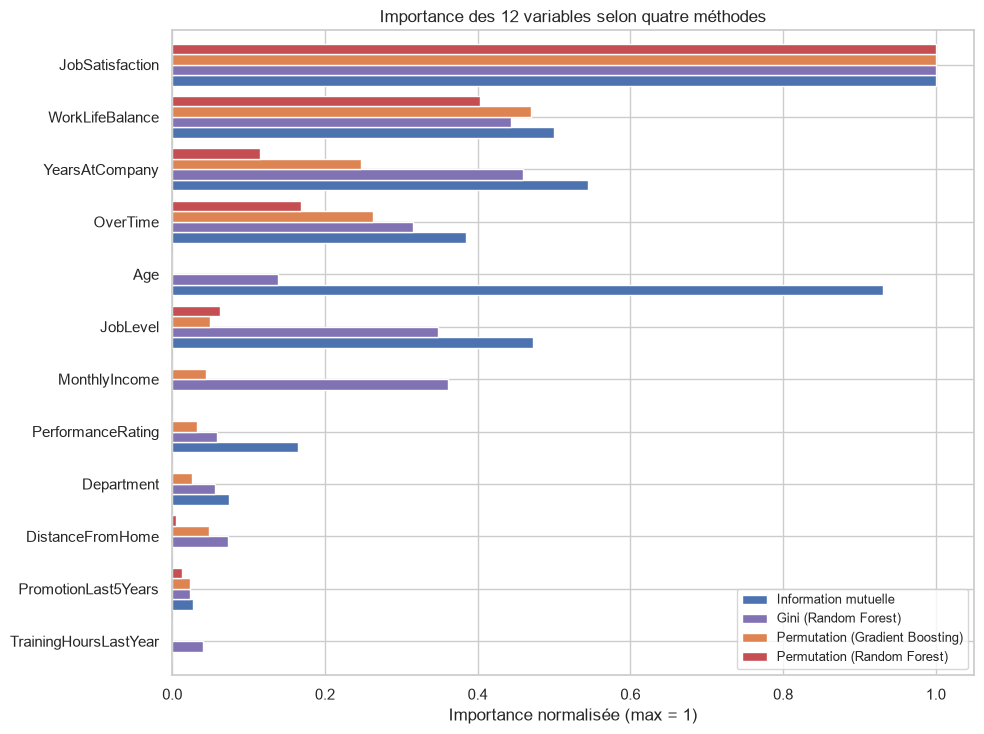

Corrélation de rang (Spearman) entre méthodes :


,Information mutuelle,Gini (Random Forest),Permutation (Gradient Boosting),Permutation (Random Forest)
Information mutuelle,1.000,0.641,0.507,0.493
Gini (Random Forest),0.641,1.000,0.825,0.545
Permutation (Gradient Boosting),0.507,0.825,1.000,0.860
Permutation (Random Forest),0.493,0.545,0.860,1.000


In [15]:
mi = mutual_information_raw(X_train, y_train)
rf_pipe = models["Random Forest"].calibrated_classifiers_[0].estimator           # pipeline ajusté sous la calibration
gini = aggregate_importance(rf_pipe[:-1].get_feature_names_out(), rf_pipe[-1].feature_importances_)
perm = {n: pd.Series(permutation_importance(models[n], X_test, y_test, scoring="average_precision", n_repeats=10, random_state=42).importances_mean, index=X_test.columns)
        for n in (best, "Random Forest")}
imp = pd.DataFrame({"Information mutuelle": mi, "Gini (Random Forest)": gini.reindex(mi.index),
                    f"Permutation ({best})": perm[best], "Permutation (Random Forest)": perm["Random Forest"]})
imp_n = imp.apply(normalize_01)
imp.to_csv(RES / "importance_multiperspective_brute.csv"); imp_n.to_csv(RES / "importance_multiperspective.csv")
order_v = imp_n.mean(axis=1).sort_values().index
imp_n.loc[order_v].plot.barh(figsize=(10, 7.5), width=.8, color=["#4c72b0", "#8172b3", "#dd8452", "#c44e52"])
plt.xlabel("Importance normalisée (max = 1)"); plt.title("Importance des 12 variables selon quatre méthodes"); plt.legend(fontsize=9, loc="lower right")
plt.tight_layout(); savefig("34_importance_multiperspective.png"); plt.show()
print("Corrélation de rang (Spearman) entre méthodes :")
imp.corr(method="spearman")

**Interprétation.**
- **Consensus fort** : `JobSatisfaction` est première pour les quatre méthodes (importance normalisée = 1) et `WorkLifeBalance` seconde pour toutes (0,40 à 0,50). `OverTime` et `YearsAtCompany` suivent (0,12 à 0,55 selon la méthode). Les autres variables sont proches de zéro par permutation. Ce sont les variables déjà repérées par l'EDA, la régression logistique et la sélection de variables (notebook 04).
- **Désaccords instructifs.** `Age` est 2ᵉ pour l'information mutuelle (0,93) mais d'importance nulle par permutation : lié au départ pris seul, mais **redondant** dès que `YearsAtCompany` et `JobLevel` sont connus (ρ de Spearman Age–YearsAtCompany = 0,64) ; les valeurs d'information mutuelle brutes sont d'ailleurs très faibles (≤ 0,006), donc peu fiables. `MonthlyIncome` et `JobLevel` ont une importance de Gini élevée (0,36 et 0,35) mais quasi nulle par permutation : le Gini **surestime les variables continues ou corrélées**, leur effet étant porté par le trio colinéaire `JobLevel`–`MonthlyIncome`–`YearsAtCompany`.
- Les méthodes de même nature s'accordent le mieux (permutation GB vs RF : ρ = 0,86 ; Gini vs permutation GB : 0,83), l'information mutuelle moins (≈ 0,5). **Pour interpréter, privilégier la permutation**, qui mesure l'effet réel sur la performance du modèle.

---
# 9. Stabilité des métriques entre plis de validation croisée
Distribution, sur les 5 plis, de l'AP et de la ROC-AUC de la meilleure configuration de chaque modèle (résultats du notebook 03, en cache). Une métrique stable d'un pli à l'autre inspire confiance.

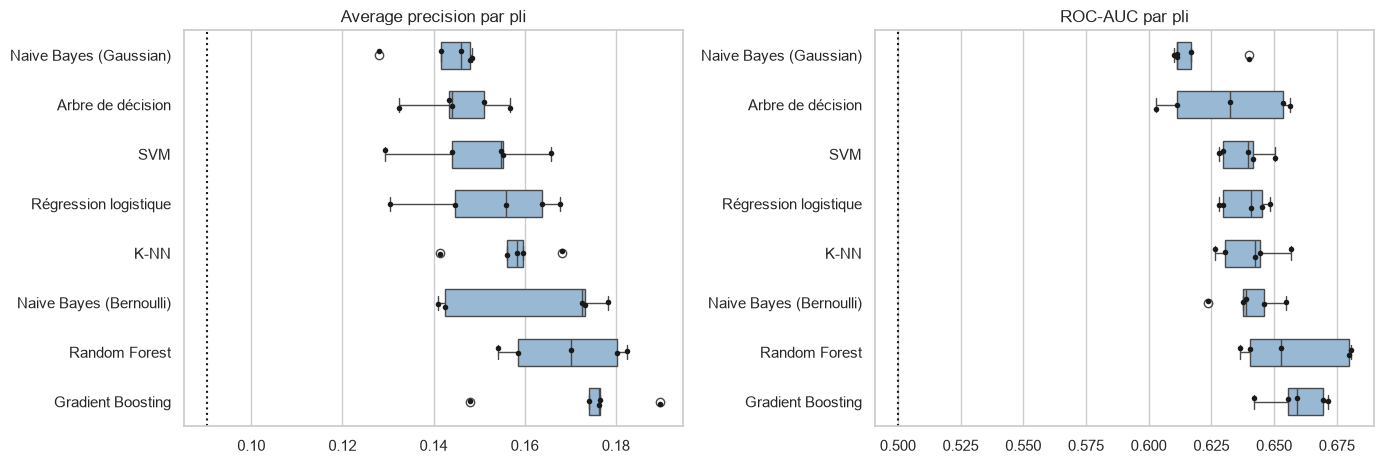

,AP moyenne,AP écart-type,AUC moyenne,AUC écart-type
Gradient Boosting,0.173,0.015,0.659,0.012
Random Forest,0.169,0.013,0.658,0.021
Naive Bayes (Bernoulli),0.162,0.018,0.640,0.012
K-NN,0.157,0.010,0.640,0.012
Régression logistique,0.153,0.015,0.638,0.009
SVM,0.150,0.014,0.638,0.009
Arbre de décision,0.146,0.009,0.631,0.024
Naive Bayes (Gaussian),0.142,0.009,0.618,0.013


In [16]:
searches = {n: fit_search(n, s, X_train, y_train) for n, s in get_searches().items()}
ap_f, auc_f = fold_scores(searches, "ap"), fold_scores(searches, "roc_auc")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, f, ttl, ref in zip(axes, (ap_f, auc_f), ("Average precision par pli", "ROC-AUC par pli"), (y_train.mean(), 0.5)):
    o = f.mean().sort_values().index
    sns.boxplot(data=f[o], orient="h", ax=ax, color=BLUE, width=.55); sns.stripplot(data=f[o], orient="h", ax=ax, color="k", size=4)
    ax.axvline(ref, color="k", ls=":"); ax.set_title(ttl)
plt.tight_layout(); savefig("35_stabilite_plis.png"); plt.show()
pd.DataFrame({"AP moyenne": ap_f.mean(), "AP écart-type": ap_f.std(), "AUC moyenne": auc_f.mean(), "AUC écart-type": auc_f.std()}).sort_values("AP moyenne", ascending=False)

**Interprétation.** Sur les 5 plis, l'écart-type de l'AP va de 0,009 à 0,018 et celui de la ROC-AUC de 0,009 à 0,024, du même ordre que les écarts entre modèles (0,01 à 0,03 d'AP) : un pli de plus ou de moins pourrait changer certains rangs. Gradient Boosting (0,173) et Random Forest (0,169) ont les moyennes les plus hautes. **Tous les plis de tous les modèles restent au-dessus de Zero-R** (AP ≥ 0,128 contre 0,09 ; ROC-AUC ≥ 0,603 contre 0,5) : la performance ne dépend pas d'un « bon » découpage.

---
# 10. Tableau de synthèse pour le rapport
Format du tableau principal du rapport (seuil optimisé choisi sur le train ; IC à 95 % entre crochets pour la ROC-AUC).

In [17]:
rep = pd.DataFrame({
    "Accuracy": M_opt["accuracy"], "Précision": M_opt["precision"], "Rappel": M_opt["recall"], "F1": M_opt["f1"],
    "ROC-AUC": M_opt["roc_auc"], "IC 95 % ROC-AUC": [f"[{ci[n].loc['roc_auc', 'ic_bas']:.3f} ; {ci[n].loc['roc_auc', 'ic_haut']:.3f}]" for n in names],
    "PR-AUC": M_opt["pr_auc"], "MCC": M_opt["mcc"], "Brier": M_opt["brier"], "Rang moyen": ranks["rang_moyen"].reindex(M_opt.index),
}).sort_values("ROC-AUC", ascending=False)
rep.to_csv(RES / "tableau_metriques_rapport.csv")
rep

,Accuracy,Précision,Rappel,F1,ROC-AUC,IC 95 % ROC-AUC,PR-AUC,MCC,Brier,Rang moyen
Gradient Boosting,0.760,0.176,0.448,0.253,0.665,[0.622 ; 0.705],0.173,0.163,0.080,1.000
Régression logistique,0.761,0.168,0.414,0.239,0.656,[0.614 ; 0.695],0.160,0.145,0.080,3.125
SVM,0.739,0.162,0.453,0.239,0.655,[0.614 ; 0.695],0.158,0.146,0.080,3.625
Random Forest,0.756,0.164,0.414,0.235,0.655,[0.610 ; 0.697],0.163,0.140,0.080,4.000
K-NN,0.809,0.186,0.326,0.236,0.651,[0.605 ; 0.691],0.169,0.144,0.080,3.250
Naive Bayes (Bernoulli),0.758,0.155,0.376,0.219,0.634,[0.588 ; 0.675],0.152,0.119,0.081,6.000
Naive Bayes (Gaussian),0.675,0.132,0.464,0.206,0.625,[0.577 ; 0.667],0.143,0.099,0.081,7.125
Arbre de décision,0.744,0.138,0.348,0.197,0.608,[0.562 ; 0.650],0.137,0.089,0.081,7.875
Zero-R,0.909,0.000,0.000,0.000,0.500,[0.500 ; 0.500],0.090,0.000,0.082,NaN


| Question | Réponse |
|---|---|
| Meilleur modèle selon les métriques | **Gradient Boosting**, 1er sur les 8 métriques du classement (rang moyen 1,0) : F1 0,253, MCC 0,163, ROC-AUC 0,665 [0,622 ; 0,705], PR-AUC 0,173 |
| L'écart avec les autres est-il établi ? | **Non** face à régression logistique, SVM, Random Forest et K-NN : IC qui se recouvrent, classement qui change selon le budget d'alertes. Oui face à l'arbre seul, GaussianNB et BernoulliNB (test apparié, notebook 03) |
| Quelles métriques citer ? | **ROC-AUC et PR-AUC** (indépendantes du seuil, avec IC) puis **F1, MCC, précision et rappel au seuil optimisé**. Ne pas citer l'accuracy seule : Zero-R fait mieux (0,909) |
| Le seuil 0,5 est-il utilisable ? | **Non** : aucun modèle n'émet d'alerte à 0,5. Seuil choisi sur le train (0,118 pour Gradient Boosting) |
| Quelle qualité réelle ? | **Modeste** : MCC ≤ 0,16 ; 1 alerte sur 6 exacte (précision 0,18) ; 45 % des départs détectés ; lift ≈ 2,3 sur les 10 % les plus à risque |
| Quelles variables expliquent le départ ? | Consensus des 4 méthodes : **`JobSatisfaction`** (loin devant), **`WorkLifeBalance`**, puis `OverTime` et `YearsAtCompany` |

**Limites.** (1) 181 départs seulement dans le test : tous les IC sont larges. (2) Le bootstrap suppose un test représentatif ; il n'élimine pas l'aléa du découpage train/test lui-même (la validation croisée du notebook 03 le complète). (3) Seuils choisis sur le train puis fixés : l'IC du F1 ne tient pas compte de l'incertitude sur ce seuil. (4) Importance par information mutuelle peu fiable à ce niveau de signal.